# 02 — Entraînement

**Deux modèles**, entraînés exactement avec les mêmes données, augmentations et perte :

| | Baseline | Modèle principal |
|---|---|---|
| Architecture | petit CNN (4 blocs conv) | DenseNet-121 (Huang et al., 2017) |
| Initialisation | aléatoire | pré-entraîné sur ImageNet |
| Pourquoi | point de comparaison | référence historique en radio thoracique (CheXNet, Rajpurkar et al., 2017) |

**Choix communs, et pourquoi :**
- **Perte pondérée** (`BCEWithLogitsLoss` avec `pos_weight = n_normales / n_pneumonies`) : le train
  contient ~74 % de pneumonies ; sans pondération, le modèle serait poussé à tout prédire « pneumonie ».
- **Early stopping sur l'AUC de validation** : l'AUC ne dépend pas du seuil et n'est pas trompée par
  le déséquilibre, contrairement à l'accuracy. On garde les poids de la meilleure époque.
- **Fine-tuning en 2 temps** (DenseNet) : d'abord la tête seule (les features ImageNet sont gelées,
  pour ne pas les abîmer avec des gradients aléatoires venant d'une tête non entraînée), puis tout le
  réseau avec un petit learning rate.
- **Graine fixe (42)** : mêmes tirages à chaque exécution.
- Entraînement **court**, adapté à la machine : GPU NVIDIA MX330 avec seulement 2 Go de mémoire.
  DenseNet-121 ne tenait pas en mémoire, même avec 16 images par batch. Deux techniques ont permis
  de l'entraîner, sans changer le modèle :
  - **précision mixte (AMP)** : les calculs se font en float16 quand c'est sans risque, ce qui
    divise par ~2 la mémoire des activations ;
  - **checkpointing** (`memory_efficient=True`) : les activations internes des blocs denses sont
    recalculées pendant la rétropropagation au lieu d'être stockées.

  Mesure réelle : pic de 0,60 Go pour un batch de 16, ~23 images/s, soit environ 3,5 min par époque.
- La baseline, très légère, a été entraînée **sur le CPU en parallèle**, pour libérer le GPU.

In [1]:
import sys
from pathlib import Path

# Le notebook est dans notebooks/ : on remonte à la racine du dépôt pour importer src/
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.precision", 3)
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"dpi": 90, "bbox_inches": "tight"}
import torch
from src.data import charger_split_et_cache, dataset_pour, DOSSIER_FIGURES, DOSSIER_RESULTATS
from src.models import creer_modele
MARINE, GRIS = "#14284b", "#52514e"
df, cache = charger_split_et_cache()
print(df.groupby(["split", "classe"]).size().unstack())

classe  NORMAL  PNEUMONIA
split                    
test       234        390
train     1156       3328
val        193        555


## 1. Les augmentations, visuellement

Petite rotation (±10°), translation (5 %), zoom (±5 %), luminosité/contraste (±10 %). Pas de flip :
une radio n'est jamais à l'envers, et le cœur est à gauche (un flip horizontal créerait une anatomie
inversée).

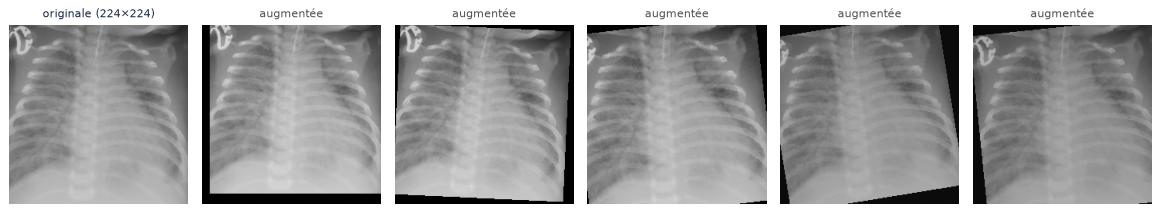

In [2]:
torch.manual_seed(0)
ds = dataset_pour("train", df, cache)
i = int(np.flatnonzero(ds.labels.numpy() == 1)[0])
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6), dpi=130)
axes[0].imshow(ds.images[i], cmap="gray", vmin=0, vmax=255); axes[0].set_title("originale (224×224)", fontsize=9, color=MARINE)
for ax in axes[1:]:
    x, _ = ds[i]
    ax.imshow(x[0] * 0.229 + 0.485, cmap="gray", vmin=0, vmax=1); ax.set_title("augmentée", fontsize=9, color=GRIS)
for ax in axes: ax.axis("off")
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "augmentations.png", bbox_inches="tight")

## 2. Taille des modèles

In [3]:
for nom in ["baseline", "densenet121"]:
    m = creer_modele(nom, pretrained=False)
    print(f"{nom:12s} : {sum(p.numel() for p in m.parameters()):>10,} paramètres")

baseline     :     97,809 paramètres
densenet121  :  6,954,881 paramètres


## 3. Entraînement

L'entraînement a été lancé **en ligne de commande** (plus robuste pour un long calcul) avec les
commandes ci-dessous ; les journaux réels sont affichés tels quels.

```
python -m src.train --modele densenet121 --epochs-tete 2 --lr-tete 1e-3 --epochs 8 --lr 1e-4 --patience 3 --batch 16 --amp
python -m src.train --modele baseline --epochs 15 --lr 1e-3 --patience 4 --batch 32 --cpu
```

In [4]:
print((DOSSIER_RESULTATS / "logs" / "train_baseline.log").read_text(encoding="utf-8"))

D:\Projet_ChestXray\src\data.py:229: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\utils\tensor_numpy.cpp:212.)
  self.labels = torch.as_tensor(labels, dtype=torch.float32)
Appareil : cpu (CPU)
Train : 4484 images (3328 pneumonies, 1156 normales) ; val : 748 ; pos_weight = 0.347

=== Phase « complet » : 15 époques max, lr=0.001, 97,809 paramètres entraînables ===
[ 1] complet perte train 0.1839 | val 0.2348 | AUC 0.9573 | sens 0.641 | spec 0.984 | 188s  <- meilleur
[ 2] complet perte train 0.1490 | val 0.1178 | AUC 0.9680 | sens 0.885 | spec 0.959 | 215s  <- meilleur
[ 3] complet perte train 

In [5]:
print((DOSSIER_RESULTATS / "logs" / "train_densenet121.log").read_text(encoding="utf-8"))

D:\Projet_ChestXray\src\data.py:229: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\utils\tensor_numpy.cpp:212.)
  self.labels = torch.as_tensor(labels, dtype=torch.float32)
Appareil : cuda (NVIDIA GeForce MX330)
Train : 4484 images (3328 pneumonies, 1156 normales) ; val : 748 ; pos_weight = 0.347

=== Phase « tete » : 2 époques max, lr=0.001, 1,025 paramètres entraînables ===
[ 1] tete    perte train 0.1613 | val 0.1651 | AUC 0.9734 | sens 0.726 | spec 0.995 | 96s  <- meilleur
[ 2] tete    perte train 0.1001 | val 0.1301 | AUC 0.9755 | sens 0.809 | spec 0.984 | 99s  <- meilleur

=== Phase « c

## 4. Courbes d'apprentissage

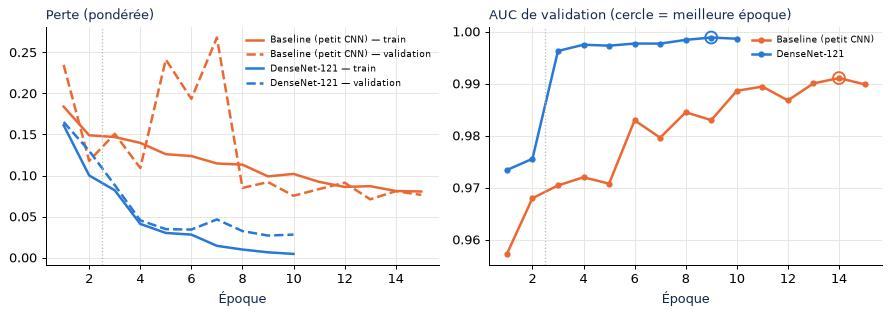

In [6]:
import json
COUL = {"baseline": "#eb6834", "densenet121": "#2a78d6"}
LIB = {"baseline": "Baseline (petit CNN)", "densenet121": "DenseNet-121"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), dpi=150)
for nom in ["baseline", "densenet121"]:
    h = pd.DataFrame(json.loads((DOSSIER_RESULTATS / f"historique_{nom}.json").read_text(encoding="utf-8")))
    axes[0].plot(h.epoque, h.perte_train, color=COUL[nom], lw=2, label=f"{LIB[nom]} — train")
    axes[0].plot(h.epoque, h.perte_val, color=COUL[nom], lw=2, ls="--", label=f"{LIB[nom]} — validation")
    axes[1].plot(h.epoque, h.val_auc, color=COUL[nom], lw=2, marker="o", ms=4, label=LIB[nom])
    best = h.loc[h.val_auc.idxmax()]
    axes[1].scatter(best.epoque, best.val_auc, s=90, facecolor="none", edgecolor=COUL[nom], lw=1.5, zorder=3)
    if nom == "densenet121" and (h.phase == "tete").any():
        fin_tete = h[h.phase == "tete"].epoque.max()
        for ax in axes: ax.axvline(fin_tete + 0.5, color="#b9b8b1", ls=":", lw=1)
axes[0].set_title("Perte (pondérée)", loc="left", color=MARINE, fontsize=10)
axes[1].set_title("AUC de validation (cercle = meilleure époque)", loc="left", color=MARINE, fontsize=10)
for ax in axes:
    ax.set_xlabel("Époque", color=MARINE)
    for c in ["top", "right"]: ax.spines[c].set_visible(False)
    ax.grid(color="#e7e6e1"); ax.set_axisbelow(True); ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(DOSSIER_FIGURES / "courbes_apprentissage.png", bbox_inches="tight")

In [7]:
for nom in ["baseline", "densenet121"]:
    r = json.loads((DOSSIER_RESULTATS / f"entrainement_{nom}.json").read_text(encoding="utf-8"))
    print(f"{nom:12s} meilleure AUC val = {r['meilleure_val_auc']:.4f} (époque {r['meilleure_epoque']}/"
          f"{r['epoques_effectuees']}), durée {r['duree_totale_min']:.1f} min sur {r['appareil']}")

baseline     meilleure AUC val = 0.9911 (époque 14/15), durée 38.6 min sur CPU
densenet121  meilleure AUC val = 0.9989 (époque 9/10), durée 43.6 min sur NVIDIA GeForce MX330


### Observations
- **DenseNet-121** : meilleure AUC de validation **0,9989** (époque 9 sur 10), 43,6 min sur la MX330. Avec la tête seule, l'AUC plafonne vers 0,975 ; dès qu'on ajuste tout le réseau, elle passe à 0,996. Les features ImageNet sont utiles, mais les adapter aux radiographies compte beaucoup.
- En fin d'entraînement, la perte d'entraînement (0,0045) devient bien plus faible que celle de validation (~0,03) : le modèle commence à **sur-apprendre**, sans que l'AUC de validation se dégrade. L'early stopping ne s'est pas déclenché : on a atteint la limite de 8 époques fixée pour tenir dans la nuit.
- **Baseline** : meilleure AUC de validation **0,9911** (époque 14 sur 15, 38,6 min sur CPU). Elle progressait encore : quelques époques de plus l'auraient peut-être un peu améliorée. Au seuil 0,5, sa sensibilité de validation oscille beaucoup (0,65 à 0,98 selon l'époque) : son seuil est instable.
- Les deux AUC de validation sont très élevées, car la validation vient de la **même distribution** que le train. La vraie mesure est le test officiel (notebook 03).